# Does the decomposition see the difference between teaching the model something new and strengthening something it already has?

*Round 7, 2026-10-20. Plan: `reports/plans/2026-10-20_plan_new-vs-existing-signatures.md`. Record: `reports/analyses/2026-10-20_analysis_new-vs-existing-signatures.md`.*

## The answer

We taught the model two things it can already do, repeating a word, and two things it cannot, an arbitrary word-to-word mapping, and looked for any per-subcomponent number that tells the two apart. Nothing about the weight update does. It is equally expressible by the subcomponents, it lands on the same kind of subcomponents, and two training seeds agree equally. The difference sits entirely in how the frozen importance function reads the trained model. For repeating a word it switches on about 120 existing subcomponents, which then carry the behaviour. For the mapping it switches on about 35, and the behaviour runs through subcomponents it keeps off.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

R = Path('../experiments/new_vs_existing/results')
F = Path('../experiments/new_vs_existing/figures')
out = json.loads((R / 'new_vs_existing.json').read_text())
tasks, score = out['tasks'], out['score']
CLASS = {'existing': 'copy', 'new': 'mapping'}
rows = [(n, CLASS[t['cls']], s, r) for n, t in tasks.items() for s, r in t['seeds'].items()]

## What we were trying to test

Every round so far asked whether some map from a fine-tune's update to the decomposition passes VPD's own checks. This round steps back and asks what the decomposition can see about the update at all. If post-training sometimes strengthens a mechanism the model has and sometimes builds a new one, the decomposition's account of those two updates should look different somewhere. We went looking for where.

The format is the key → value task of round 6. A Pile window of 41 tokens has one token replaced by a rare marker and the next by a common word, the key. The model is fine-tuned to predict a particular word after that pair. In the two **copy tasks** the word is the key itself: "marker the" is followed by "the". The model has copying machinery, so this strengthens something it can do. In the two **mapping tasks** the word is a fixed random other word, the same 32 pairs every time: "marker the" is followed by "copy", say. Nothing in the model does this. Each task teaches its 32 pairs in one fine-tune. The second task of each class uses a different set of 32 keys, so within a class the two tasks differ in words and not in rule. The only designed difference between the classes is the rule.

Each task gets a full-weight fine-tune of the 24 decomposed matrices, at two seeds: eight fine-tuned states in all. A state is scored at its first checkpoint that has learned the task, which means a held-out probability of the target of at least one half. Nothing else is trained. The importance function Γ, the residual Δ and the released subcomponents are as published, so every number below is about how the published decomposition reads an update it was never fitted to.

Five numbers were filed with a rule, one per claim about what a complete decomposition would show. Throughout, T is the hundred alive subcomponents the lift moves most, where the lift writes the update as the least-norm change $(dU, dV)$ of the alive subcomponents with $dU V^\top + U dV^\top \approx \delta W$.

1. **How much of the update the subcomponents cannot express.** The share of the update's input-weighted energy outside every alive subcomponent's read and write directions, divided by what a random update of the same per-matrix size reads. A value of 1 means the update is no more expressible than noise. A random update is pushed through the same number as the check that the null really reads 1.
2. **How much of the learned behaviour is left in Δ after the lift.** Of the fine-tune's gain in the target's log-odds at the trigger, the share that the lifted state carries only through Δ. Leaving the whole update in Δ reads 1 by construction.
3. **Were the moved subcomponents doing the job already?** In the original model, remove T's rank-1 matrices from the weights and read how far the target's log-odds at the trigger fall. The reference is five random sets of the same size per matrix, drawn from the same decile of causal importance at the trigger. A ratio of 1 means T is no more relevant than chance.
4. **Which route the behaviour takes.** The route split of the lifted state at the trigger: the share carried because the frozen Γ switches existing subcomponents on for the new activations, written $r$, and the share carried by subcomponents Γ keeps switched off, written $e_{gate}$. Round 6 saw these two shares swap between an identity task and a random map, and that is the one separation already known.
5. **Do two seeds move the same subcomponents?** The Jaccard overlap of the two seeds' T sets, against the overlap of two random sets of the same size.

Six more numbers are reported with an expected direction only. They are T's mean causal importance at the trigger before and after the update, the share of the lift's energy on subcomponents switched off at the trigger, and how often T is on over Pile. Also how many subcomponents Γ switches on and where they sit, and Γ coverage of the task gradient.

## What we expected, and why

Suppose the decomposition were a complete story of the model: every behaviour is produced by the subcomponents Γ marks important, and every mechanism the model has is a sparse set of them. Then strengthening an existing mechanism should show as a set of subcomponents that are already on and relevant before training, that the update lands on, and that two seeds agree on. Building a new one should show as none of those, with the behaviour having nowhere to go but the switched-off subcomponents or Δ.

So we filed five predictions. The copy tasks' updates are more expressible, with a ratio to the null of at most 0.7 against at least 0.85. The residual share does **not** separate, because round 6 read 0.13 and 0.18 for the two classes. The relevance ratio is at least 3 for the copy tasks and between 0.5 and 2 for the mappings. The route separates on both shares. The seeds agree more on the copy tasks. A number separates the classes when their ranges do not overlap and the gap between them is larger than the wider within-class range.

## What we observed

### 1. Which of the five numbers separates the two classes?

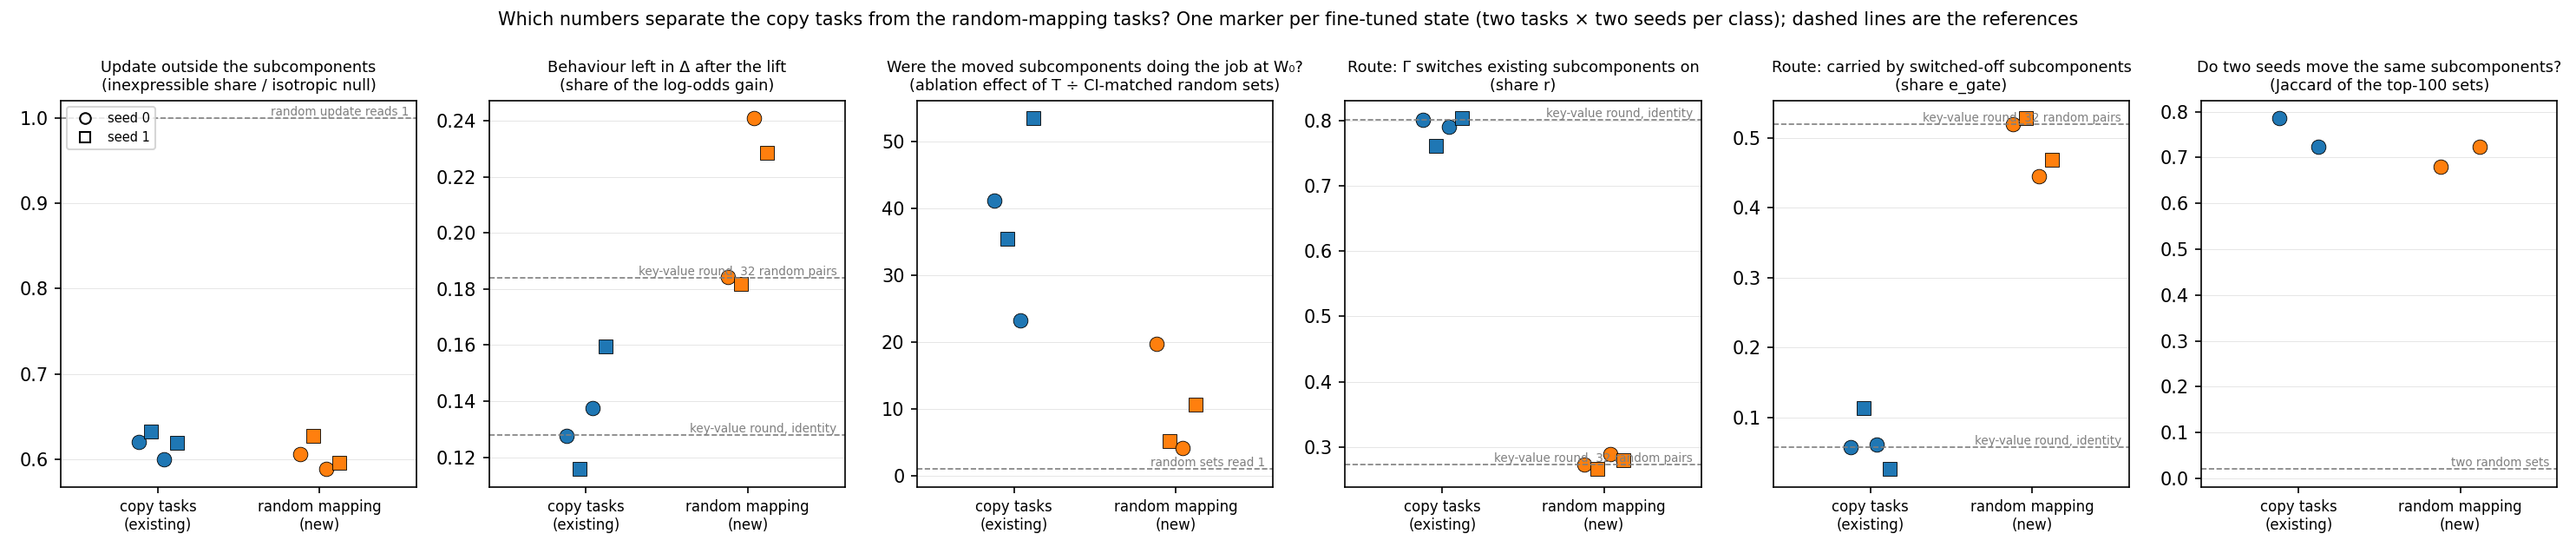

In [2]:
display(Image(F / 'separation.png', width=1400))

**Reading it.** Only the route does. In the fourth panel the copy tasks sit at a re-switching share of 0.76 to 0.80 and the mappings at 0.27 to 0.29. In the fifth the switched-off share is 0.03 to 0.11 for the copy tasks and 0.45 to 0.53 for the mappings. The dashed lines from round 6 run through each cluster. The first panel shows the update is equally expressible in both classes, a ratio of about 0.6 to the random null for every state. The second panel shows the share of the behaviour left in Δ is a little higher for the mappings. But the gap between the classes is smaller than the spread inside a class, as filed. In the third panel the moved subcomponents are far more relevant than chance in both classes. The ratios are 23 to 54 for the copy tasks and 4 to 20 for the mappings, and the spread within the copy tasks alone is wider than the gap. In the last panel the two seeds of a task move the same subcomponents about equally often in both classes, an overlap near 0.7 against 0.02 for random sets.

In [3]:
pd.DataFrame([{'task': n, 'class': c, 'seed': s, 'step': r['scored_step'], 'held-out P': round(r['p_o'], 2),
               'inexpressible / null': round(r['inexpressible']['ratio'], 2), 'left in Δ': round(r['routes_lift']['shares']['e_delta'], 2),
               'relevance ratio': round(r['relevance_W0']['k_lo'], 1), 'r': round(r['routes_lift']['shares']['r'], 2),
               'switched-off share': round(r['routes_lift']['shares']['e_gate'], 2)} for n, c, s, r in rows]).set_index(['task', 'class', 'seed'])

step  held-out P  inexpressible / null  left in Δ  \
task     class   seed                                                      
ident32  copy    0       10        0.96                  0.62       0.13   
                 1       10        0.96                  0.63       0.12   
ident32b copy    0       10        0.98                  0.60       0.14   
                 1       10        0.94                  0.62       0.16   
rand32   mapping 0       10        0.59                  0.61       0.18   
                 1       10        0.55                  0.63       0.18   
rand32b  mapping 0       30        1.00                  0.59       0.24   
                 1       30        0.99                  0.60       0.23   

                       relevance ratio     r  switched-off share  
task     class   seed                                             
ident32  copy    0                41.2  0.80                0.06  
                 1                35.5  0.76                0.11  
ident32b copy    0                23.3  0.79                0.06  
                 1                53.5  0.80                0.03  
rand32   mapping 0                19.7  0.27                0.52  
                 1                 5.2  0.27                0.53  
rand32b  mapping 0                 4.2  0.29                0.45  
                 1                10.7  0.28                0.47

### 2. Where does the update land, and were those subcomponents doing the job already?

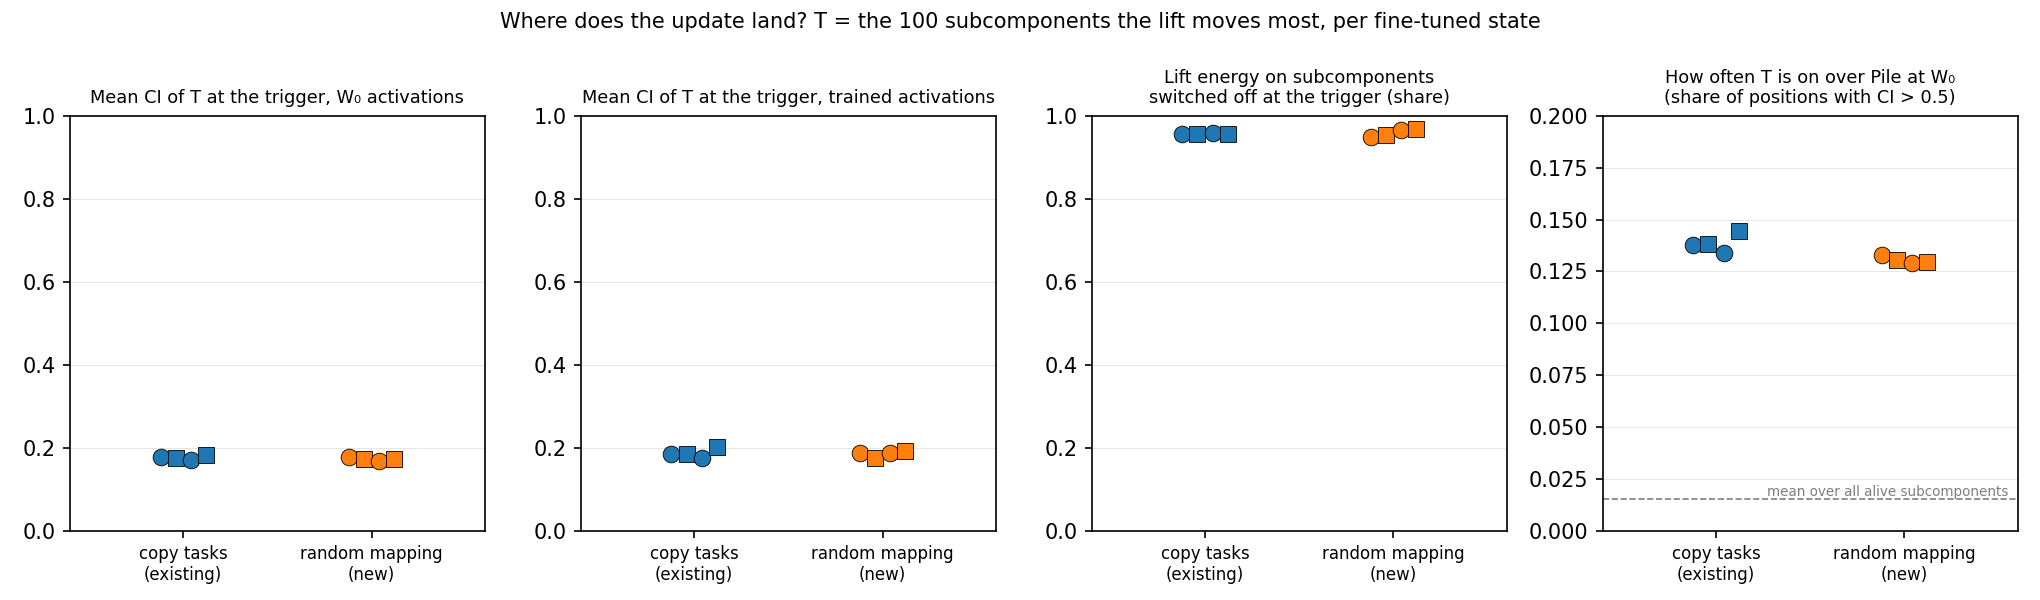

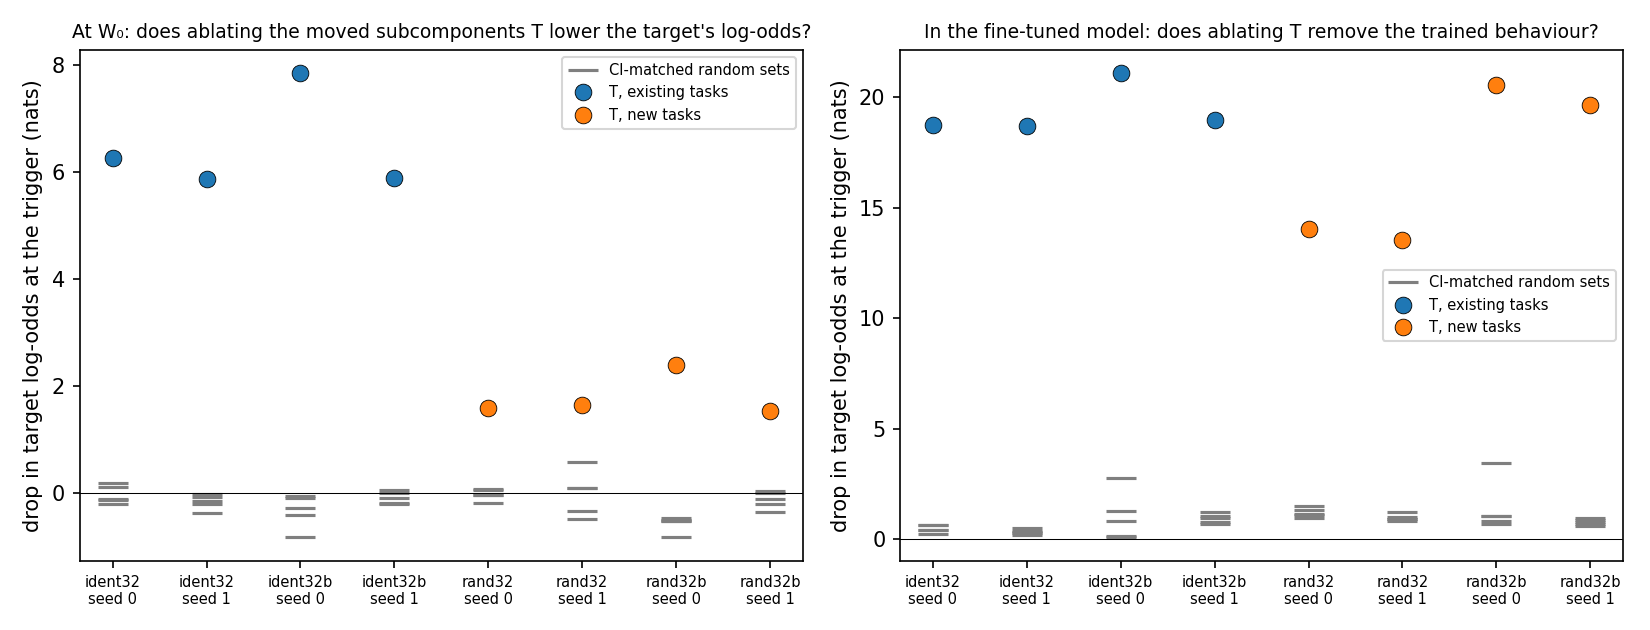

In [4]:
display(Image(F / 'landing.png', width=1400))
display(Image(F / 'relevance.png', width=1200))

**Reading it.** The update lands in the same place for both classes, and that place is busy rather than specific. The hundred subcomponents the lift moves most have a mean causal importance of about 0.18 at the trigger, before and after training, in all eight states. More than 95% of the lift's energy sits on subcomponents whose importance at the trigger is below one half. These subcomponents are on at about 13% of Pile positions, nine times the alive average, so the update goes to subcomponents the model uses everywhere. In both classes they come mostly from the input matrices of the layer-1 and layer-3 MLPs.

The relevance check says the same thing from the other side. Removing those hundred subcomponents from the original model changes its next-token distribution at the trigger by 10 to 12 nats, against half a nat for a random set of matched importance. The copy target falls by 6 to 8 nats. The mapping target falls by 1.5 to 2.4 nats, so even the arbitrary target was supported by these subcomponents before training. No mechanism story predicts that. In the fine-tuned model, removing them takes away the whole gain, again in both classes. The honest reading is that the update moves the subcomponents that matter at that position, whatever is being taught. The relevance number as designed cannot tell "the mechanism for this behaviour" from "important here in general".

### 3. How does the frozen Γ respond to the trained model?

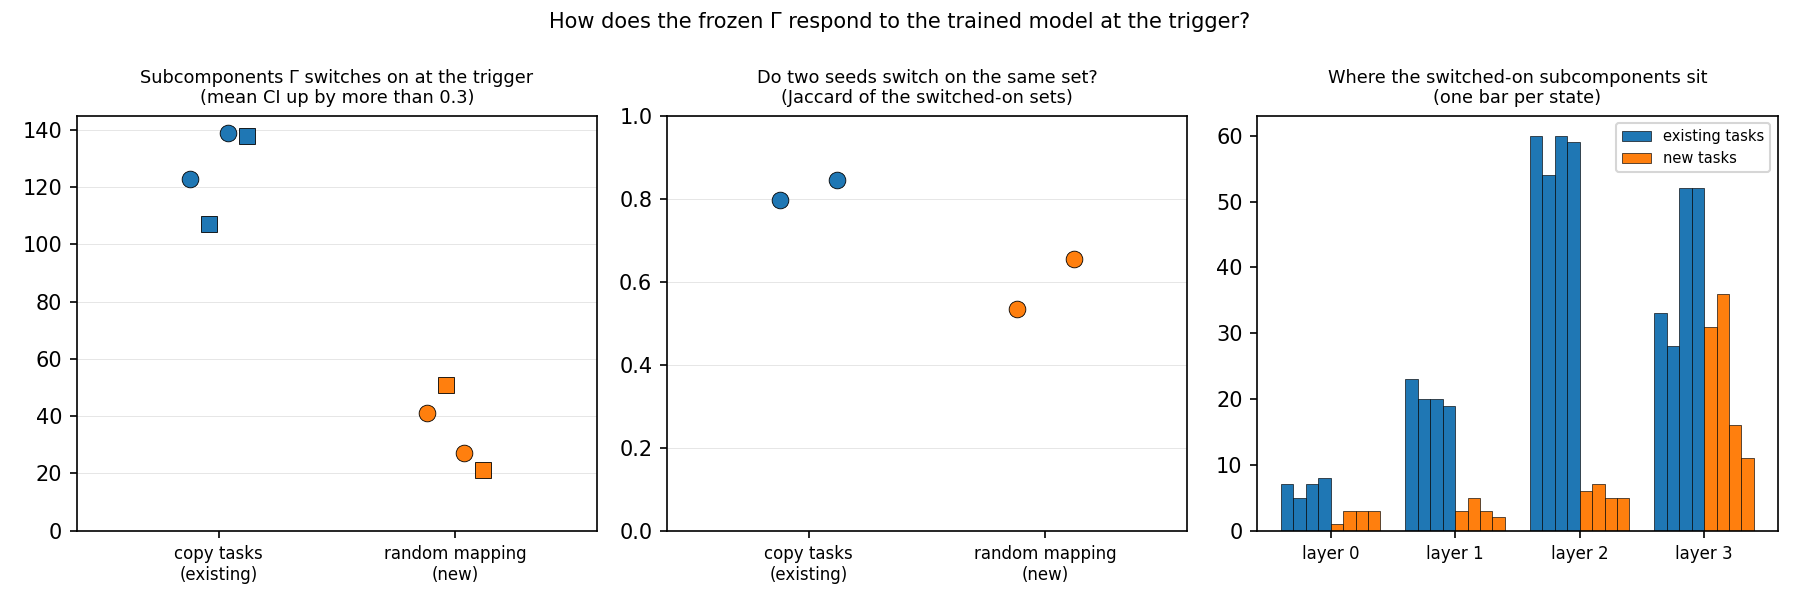

In [5]:
display(Image(F / 'gamma.png', width=1300))

**Reading it.** Here the classes part. For the copy tasks Γ switches on 107 to 139 subcomponents at the trigger. For the mappings it switches on 21 to 51, and almost nothing is switched off in either class. The two seeds of a copy task switch on sets that overlap by about 0.8. The two seeds of a mapping overlap by about 0.6. The switched-on subcomponents of the copy tasks sit mainly in the layer-2 attention matrices and the layer-3 MLP, where a copying mechanism would plausibly live. Those of the mappings sit almost only in layer 3. These switched-on subcomponents are not the ones the update moved: their overlap with T is 0.03 or less in every state. So for strengthening, a diffuse weight change shifts the activations enough for Γ to switch on a coherent, pre-existing set, and that set carries the behaviour. For creating, Γ finds much less to switch on, and the behaviour is carried by subcomponents it leaves off.

In [6]:
pd.DataFrame([{'task': n, 'class': c, 'seed': s, 'switched on': r['S_on']['size'], 'switched off': r['S_on']['size_off'],
               'T mean CI at trigger': round(r['T']['g0_mean'], 2), 'lift energy on switched-off': round(r['T']['energy_share_off_at_trigger'], 2),
               'T on-rate over Pile': round(r['T']['pile_on_rate_mean'], 3), 'overlap T with switched-on': round(r['T']['jaccard_S_on'], 3)}
              for n, c, s, r in rows]).set_index(['task', 'class', 'seed'])

switched on  switched off  T mean CI at trigger  \
task     class   seed                                                    
ident32  copy    0             123             5                  0.18   
                 1             107             5                  0.17   
ident32b copy    0             139             9                  0.17   
                 1             138             9                  0.18   
rand32   mapping 0              41             0                  0.18   
                 1              51             0                  0.17   
rand32b  mapping 0              27             1                  0.17   
                 1              21             1                  0.17   

                       lift energy on switched-off  T on-rate over Pile  \
task     class   seed                                                     
ident32  copy    0                            0.96                0.138   
                 1                            0.96                0.138   
ident32b copy    0                            0.96                0.134   
                 1                            0.96                0.144   
rand32   mapping 0                            0.95                0.133   
                 1                            0.95                0.130   
rand32b  mapping 0                            0.97                0.129   
                 1                            0.97                0.130   

                       overlap T with switched-on  
task     class   seed                              
ident32  copy    0                          0.023  
                 1                          0.025  
ident32b copy    0                          0.021  
                 1                          0.030  
rand32   mapping 0                          0.014  
                 1                          0.007  
rand32b  mapping 0                          0.033  
                 1                          0.034

## What we learned

For the goal's second branch, "new capability" turns out to be a statement about how Γ reads the trained model. It is not a statement about the weight update written in the subcomponent basis. On every number that reads the update itself the two classes are indistinguishable. The update lands on relevant, generically busy subcomponents either way. What differs is whether the frozen Γ, shown the trained activations, finds a large existing set to switch on. That is the mechanism round 6 called reveal, now with a within-class floor behind it. It also says why every frozen-Γ map has struggled. The information that separates the two cases is not in $\delta W$ projected onto the subcomponents; it is in how Γ responds, and a map that freezes Γ cannot read it. Updating Γ, which the backlog has carried since the start, is the next thing a map needs.

## How compelling is the evidence

Two tasks and two seeds per class, all in one format and at one update size. The route separation is as wide as in round 6 and its within-class spread is 0.04, so it is robust here. The three nulls are nulls, not reversals. The predicted direction held for the relevance ratio and nearly for the residual share, but the within-class spread swallowed the gap. One confound: the second mapping task learned at step 30 with an update twice the size of the others. Its numbers match the first mapping task at step 10, so the class signature does not depend on step or size in this range. The relevance check is blind to the difference between "the mechanism for this" and "important at this position". The mapping target's drop of 1.5 nats at the original model shows that. The "repeat the current token" control over Pile had only 289 positions in 32,768 and read chance for every set, so it says nothing. The expressibility number uses the input-weighted share pooled over the matrices whose subcomponents do not already span every direction, as in rounds 4 and 5.

## Surprises

Three of the five filed separations did not happen. We predicted that the copy tasks' updates would be more expressible, that the subcomponents they move would be more relevant at the original model, and that their seeds would agree more. None of those held. The update looks the same on every update-side number. The larger surprise is that the subcomponents the update moves most are relevant at the trigger in both classes, even for a target the model gives one in a million. They are also almost disjoint from the subcomponents Γ switches on. The mechanism story we wrote down, "the update lands on the mechanism", is wrong for both classes. The update lands on the busy subcomponents, and Γ does the rest.

## What next

- Read T by relative change instead of absolute energy, and at a smaller size such as 20. If a relative T overlaps the switched-on set for the copy tasks, the "busy subcomponents" reading was an artefact of the energy ranking, and claim 2 is redone.
- Ask what the switched-on subcomponents of the copy tasks do in the original model, on Pile positions where the model copies. An attention-based copying mechanism would predict high importance there. A positive answer would make the layer-2 attention set the first named mechanism in this project.
- A map that lets Γ move, scored by the weak version on these four tasks. If the mapping tasks then pass where the frozen-Γ maps fail, the "brittle" branch is answered for this format.

## Scorecard

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| G1 | every fine-tune learns | held-out P ≥ 0.5 within 300 steps, all 8 | 6 at step 10, rand32b at step 30 | pass |
| G2 | the lift is exact | lifted state matches the fine-tune's held-out P to 1e-3, shares sum to 1 | worst difference 1e-5 | pass |
| G3 | the null reads 1 | random δW's inexpressible ratio in [0.9, 1.1], all 8 | 0.995–0.996 | pass |
| P1 | update more expressible for copy tasks | separates, existing lower | 0.60–0.63 vs 0.59–0.63 | FAIL (null) |
| P2 | residual share does not separate | no separation | 0.12–0.16 vs 0.18–0.24; gap 0.02 < within 0.06 | pass |
| P3 | moved subcomponents relevant only for copy tasks | separates, existing higher | 23–54 vs 4–20; gap 3.6 < within 30 | FAIL (direction held) |
| P4 | route separates | r and e_gate both separate | r 0.76–0.80 vs 0.27–0.29; e_gate 0.03–0.11 vs 0.45–0.53 | pass |
| P5 | seeds agree more for copy tasks | separates, existing higher | 0.72–0.79 vs 0.68–0.72 | FAIL (null) |

In [7]:
pd.DataFrame({k: {'status': v['status']} for k, v in score.items()}).T

,status
G1,pass
G2,pass
G3,pass
P1,FAIL
P2,pass
P3,FAIL
P4,pass
P5,FAIL


## Not run

- A third class the model half has, such as a plural rule. It would show whether the switched-on count grades with how much of the mechanism exists.
- T by relative change, and sizes other than 100; CI-matched sets at other deciles.
- Pile faithfulness of these states; not the question this round.
- The update's seed-to-seed overlap at matched held-out probability for the first mapping task, which only just learned at step 10.
- The fine-tunes' δW files were written to the pod's container disk and were not downloaded before it was terminated. The plan had assumed cluster storage. Re-creating them is a nine-minute run.

**Provenance.** Results `experiments/new_vs_existing/results/new_vs_existing.json`, sha256 41c5adcb…, and `tasks.json`, sha256 4e163522…. RunPod secure pod `commute-new_vs_existing` on an NVIDIA A40. Scored run 8 min 49 s, smoke 5 min 52 s. Total cost $0.24. Cluster job 26045 was cancelled before it started. Logs `cluster/logs/commute-nve-pod-{smoke,scored}.out`.